In [ ]:
!pip install pymysql

In [ ]:
import pymysql

connection = pymysql.connect(
  host = "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
  port = 4000,
  user = "2vuZ1fCueMooYfw.root",
  password = "SHSULsNYBqzbOIr2",
  database = "project",
  ssl_verify_cert = True,
  ssl_verify_identity = True,

)

In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1PVdihoEtH55ZYQnD9WztzD93fBRyTFp75zId_RSF6gk/export?format=csv"
)

TABLE_NAME = "fact_sales_normalized"
PRIMARY_KEY = "sales_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 1000000 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'fact_sales_normalized' verified/created
✅ 1000000 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1vRVByssShD9euOt8h6b1Vv5YlauXR5vi5k6shvVpTqM/export?format=csv"
)

TABLE_NAME = "dim_customers"
PRIMARY_KEY = "customer_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 100000 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_customers' verified/created
✅ 100000 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1PojpfnYE3zslpddtZ8Q-mZss4C8mJzWS/export?format=csv"
)

TABLE_NAME = "dim_salespersons"
PRIMARY_KEY = "salesperson_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 2000 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_salespersons' verified/created
✅ 2000 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1TzBNMaEl8Z7tKDAaddSnQfNGk8jRC3w-/export?format=csv"
)

TABLE_NAME = "dim_stores"
PRIMARY_KEY = "store_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 500 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_stores' verified/created
✅ 500 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1luYZMVvlXTMJnB5UodWNwHcU7kAMrZrXlwBSE3vZXyQ/export?format=csv"
)

TABLE_NAME = "dim_dates"
PRIMARY_KEY = "date_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 366 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_dates' verified/created
✅ 366 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1Uuv86l-lEIE13LI5fku9xZXOL3lnGJhWYsmL1FLlZRs/export?format=csv"
)

TABLE_NAME = "dim_products"
PRIMARY_KEY = "product_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 210 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_products' verified/created
✅ 210 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
import pandas as pd
import pymysql

# -----------------------------
# CONFIGURATION
# -----------------------------
GOOGLE_SHEET_URL = (
    "https://docs.google.com/spreadsheets/d/1uGewaIbrwSykQEe7AL1pCRZPOzU2Z9JlSq37YvDMKRQ/export?format=csv"
)

TABLE_NAME = "dim_campaigns"
PRIMARY_KEY = "campaign_sk"

DB_CONFIG = {
    "host": "gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    "port": 4000,
    "user": "2vuZ1fCueMooYfw.root",
    "password": "SHSULsNYBqzbOIr2",
    "database": "project",
    "ssl_verify_cert": True,
    "ssl_verify_identity": True
}

# -----------------------------
# DTYPE MAPPING
# -----------------------------
dtype_mapping = {
    "int64": "INT",
    "float64": "FLOAT",
    "object": "TEXT",
    "datetime64[ns]": "DATETIME",
    "bool": "BOOLEAN",
}

# -----------------------------
# LOAD GOOGLE SHEET
# -----------------------------
df = pd.read_csv(GOOGLE_SHEET_URL)

if PRIMARY_KEY not in df.columns:
    raise ValueError(
        f"Primary key '{PRIMARY_KEY}' not found in Google Sheet"
    )

print(f"✅ Loaded {len(df)} rows from Google Sheet")

# -----------------------------
# BUILD CREATE TABLE QUERY
# -----------------------------
columns_sql = []

for col, dtype in zip(df.columns, df.dtypes):

    sql_type = dtype_mapping.get(str(dtype), "TEXT")

    # Escape column names using backticks
    column_name = f"`{col}`"

    if col == PRIMARY_KEY:
        columns_sql.append(
            f"{column_name} {sql_type} PRIMARY KEY"
        )
    else:
        columns_sql.append(
            f"{column_name} {sql_type}"
        )

table_schema = ",\n    ".join(columns_sql)

create_table_query = f"""
CREATE TABLE IF NOT EXISTS `{TABLE_NAME}` (
    {table_schema}
);
"""

# -----------------------------
# DB CONNECTION
# -----------------------------
print("🔌 Connecting to TiDB Cloud...")

connection = pymysql.connect(**DB_CONFIG)
cursor = connection.cursor()

print("✅ Connected to TiDB Cloud")

# -----------------------------
# CREATE TABLE
# -----------------------------
cursor.execute(create_table_query)
connection.commit()

print(f"✅ Table '{TABLE_NAME}' verified/created")

# -----------------------------
# INSERT DATA - INCREMENTAL
# -----------------------------
placeholders = ", ".join(["%s"] * len(df.columns))

columns_str = ", ".join(
    f"`{col}`" for col in df.columns
)

insert_query = f"""
INSERT IGNORE INTO `{TABLE_NAME}` ({columns_str})
VALUES ({placeholders})
"""

data = [
    tuple(row)
    for row in df.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print(f"✅ {cursor.rowcount} new rows inserted incrementally")

# -----------------------------
# CLEANUP
# -----------------------------
cursor.close()
connection.close()

print("🎉 Incremental load completed successfully")

✅ Loaded 50 rows from Google Sheet
🔌 Connecting to TiDB Cloud...
✅ Connected to TiDB Cloud
✅ Table 'dim_campaigns' verified/created
✅ 50 new rows inserted incrementally
🎉 Incremental load completed successfully


In [ ]:
#python analysis
# Install lightweight libraries needed for database connectivity and machine learning
!pip -q install pymysql mlxtend

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from google.colab import userdata

# Secure database connection using Colab Secrets
url = URL.create(
    "mysql+pymysql",
    username="2vuZ1fCueMooYfw.root",
    password="jXlBifqLbM1ajSWP",
    host="gateway01.ap-northeast-1.prod.aws.tidbcloud.com",
    port=4000,
    database="project"
)

# Establish encrypted TLS connection
engine = create_engine(
    url,
    connect_args={
        "ssl_verify_cert": True,
        "ssl_verify_identity": True
    }
)

# Test database connection
with engine.connect() as conn:
    version = conn.execute(text("SELECT VERSION()")).scalar()

    print("Connected successfully!")
    print("TiDB Server Version:", version)

Connected successfully!
TiDB Server Version: 8.0.11-TiDB-v8.5.3-serverless


In [ ]:
# SQL query: Join the fact table with the dimension tables
query = """
SELECT
    f.sales_sk,
    f.sales_id,
    f.customer_sk,
    f.product_sk,
    f.store_sk,
    f.salesperson_sk,
    f.campaign_sk,
    f.sales_date,
    f.total_amount,
    c.customer_segment,
    p.product_name,
    p.category,
    p.brand,
    s.store_name,
    s.store_type,
    s.store_location,
    sp.salesperson_role,
    cm.campaign_name,
    cm.campaign_budget,
    d.weekday,
    d.month,
    d.quarter
FROM fact_sales_normalized f
JOIN dim_customers c ON f.customer_sk = c.customer_sk
JOIN dim_products p ON f.product_sk = p.product_sk
JOIN dim_stores s ON f.store_sk = s.store_sk
JOIN dim_salespersons sp ON f.salesperson_sk = sp.salesperson_sk
LEFT JOIN dim_campaigns cm ON f.campaign_sk = cm.campaign_sk
JOIN dim_dates d ON d.date_sk = DAYOFYEAR(f.sales_date)
"""

# Retrieve data in chunks of 200,000 records to prevent memory crashes
parts = []
for chunk in pd.read_sql(text(query), engine, chunksize=200_000):
    parts.append(chunk)
    print(f"Fetched {sum(len(p) for p in parts):,} rows")

# Combine all chunks into one DataFrame
df = pd.concat(parts, ignore_index=True)
del parts

# Convert sales_date into datetime format
df["sales_date"] = pd.to_datetime(df["sales_date"])

# Round transaction amounts to two decimal places
df["total_amount"] = df["total_amount"].astype(float).round(2)

# Remove unwanted spaces from text columns
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].str.strip()

# Validate the number of records
assert len(df) == 1_000_000, "Row count is not 1,000,000"

# Display validation results
print("\nData retrieval completed successfully!")
print("DataFrame shape:", df.shape)
print("Total revenue:", round(df["total_amount"].sum(), 2))
print("Unique store types:", df["store_type"].nunique())

Fetched 200,000 rows
Fetched 400,000 rows
Fetched 600,000 rows
Fetched 800,000 rows
Fetched 1,000,000 rows

Data retrieval completed successfully!
DataFrame shape: (1000000, 22)
Total revenue: 2750874594.76
Unique store types: 3


In [ ]:
# Check duplicate sales
print(
    "Duplicate sales:",
    df["sales_sk"].duplicated().sum()
)

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# Check data types
print("\nData types:")
display(df.dtypes)

# Preview records
print("\nFirst five records:")
display(df.head())

Duplicate sales: 0

Missing values:


,0
sales_sk,0
sales_id,0
customer_sk,0
product_sk,0
store_sk,0
salesperson_sk,0
campaign_sk,0
sales_date,0
total_amount,0
customer_segment,0



Data types:


,0
sales_sk,int64
sales_id,object
customer_sk,int64
product_sk,int64
store_sk,int64
salesperson_sk,int64
campaign_sk,int64
sales_date,datetime64[ns]
total_amount,float64
customer_segment,object



First five records:


,sales_sk,sales_id,customer_sk,product_sk,store_sk,salesperson_sk,campaign_sk,sales_date,total_amount,customer_segment,...,brand,store_name,store_type,store_location,salesperson_role,campaign_name,campaign_budget,weekday,month,quarter
0,3041,SALES_0003041,9932,164,25,773,19,2024-09-06 13:09:00,4867.32,First-time Buyer,...,Home Centre,StyleStop,Small Stores / Shops,Milwaukee,Sales Associate,Weekend Warrior Specials,513019,5,9,3
1,3042,SALES_0003042,56703,1,86,1390,5,2024-04-17 21:34:57,1826.60,Churn Risk,...,Sony,ElectroPoint,Supermarkets,Tucson,Salesperson,Flash Frenzy Friday,970860,3,4,2
2,3043,SALES_0003043,94933,62,407,26,35,2024-10-12 07:52:48,2801.62,First-time Buyer,...,Samsung,HomeHaven,Supermarkets,Baltimore,Manager,Winter Clearance Carnival,640535,6,10,4
3,3044,SALES_0003044,57720,26,170,1751,31,2024-10-25 07:00:46,4291.96,Churn Risk,...,LG,TechWorld,Small Stores / Shops,Baltimore,Salesperson,Double Points Bonanza,457117,5,10,4
4,3045,SALES_0003045,33339,150,202,724,11,2024-06-24 01:09:52,2011.70,First-time Buyer,...,Urban Ladder,NextGenMart,Large Malls / Complexes,Minneapolis,Salesperson,End of Season Sale,459061,1,6,2


In [ ]:

#Task 2: Exploratory Data Analysis (EDA)

# Check dataset dimensions

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

Total Rows: 1000000
Total Columns: 22

Column Names:
['sales_sk', 'sales_id', 'customer_sk', 'product_sk', 'store_sk', 'salesperson_sk', 'campaign_sk', 'sales_date', 'total_amount', 'customer_segment', 'product_name', 'category', 'brand', 'store_name', 'store_type', 'store_location', 'salesperson_role', 'campaign_name', 'campaign_budget', 'weekday', 'month', 'quarter']

First 5 Records:


,sales_sk,sales_id,customer_sk,product_sk,store_sk,salesperson_sk,campaign_sk,sales_date,total_amount,customer_segment,...,brand,store_name,store_type,store_location,salesperson_role,campaign_name,campaign_budget,weekday,month,quarter
0,3041,SALES_0003041,9932,164,25,773,19,2024-09-06 13:09:00,4867.32,First-time Buyer,...,Home Centre,StyleStop,Small Stores / Shops,Milwaukee,Sales Associate,Weekend Warrior Specials,513019,5,9,3
1,3042,SALES_0003042,56703,1,86,1390,5,2024-04-17 21:34:57,1826.60,Churn Risk,...,Sony,ElectroPoint,Supermarkets,Tucson,Salesperson,Flash Frenzy Friday,970860,3,4,2
2,3043,SALES_0003043,94933,62,407,26,35,2024-10-12 07:52:48,2801.62,First-time Buyer,...,Samsung,HomeHaven,Supermarkets,Baltimore,Manager,Winter Clearance Carnival,640535,6,10,4
3,3044,SALES_0003044,57720,26,170,1751,31,2024-10-25 07:00:46,4291.96,Churn Risk,...,LG,TechWorld,Small Stores / Shops,Baltimore,Salesperson,Double Points Bonanza,457117,5,10,4
4,3045,SALES_0003045,33339,150,202,724,11,2024-06-24 01:09:52,2011.70,First-time Buyer,...,Urban Ladder,NextGenMart,Large Malls / Complexes,Minneapolis,Salesperson,End of Season Sale,459061,1,6,2


In [ ]:
#Data types and missing values

# Understand column data types
print("DATA TYPES")
df.info()

# Check missing values
print("\nMISSING VALUES")
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

DATA TYPES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 22 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   sales_sk          1000000 non-null  int64         
 1   sales_id          1000000 non-null  object        
 2   customer_sk       1000000 non-null  int64         
 3   product_sk        1000000 non-null  int64         
 4   store_sk          1000000 non-null  int64         
 5   salesperson_sk    1000000 non-null  int64         
 6   campaign_sk       1000000 non-null  int64         
 7   sales_date        1000000 non-null  datetime64[ns]
 8   total_amount      1000000 non-null  float64       
 9   customer_segment  1000000 non-null  object        
 10  product_name      1000000 non-null  object        
 11  category          1000000 non-null  object        
 12  brand             1000000 non-null  object        
 13  store_name        1000000 non-nu

,Missing_Count,Missing_Percentage


In [ ]:
# Statistical summary of numerical columns

display(df.describe())

,sales_sk,customer_sk,product_sk,store_sk,salesperson_sk,campaign_sk,sales_date,total_amount,campaign_budget,weekday,month,quarter
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000.000000,1000000,1000000.000000,1000000.000000,1000000.000000,1000000.00000,1000000.000000
mean,500000.500000,50011.753443,105.604332,250.392523,1000.371922,25.502230,2024-07-30 19:54:39.402339328,2750.874595,568523.922565,4.003547,7.45766,2.832838
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2024-01-02 00:13:14,500.000000,105815.000000,1.000000,1.00000,1.000000
25%,250000.750000,24992.000000,53.000000,125.000000,501.000000,13.000000,2024-05-24 07:24:13,1628.300000,364556.000000,2.000000,5.00000,2.000000
50%,500000.500000,50027.500000,106.000000,250.000000,1000.000000,26.000000,2024-08-16 15:58:16,2750.530000,492696.000000,4.000000,8.00000,3.000000
75%,750000.250000,74980.000000,158.000000,375.000000,1500.000000,38.000000,2024-10-14 05:21:19.750000128,3875.352500,831755.000000,6.000000,10.00000,4.000000
max,1000000.000000,100000.000000,210.000000,500.000000,2000.000000,50.000000,2024-12-26 23:49:15,4999.980000,987420.000000,7.000000,12.00000,4.000000
std,288675.278933,28859.467198,60.679945,144.316563,577.265764,14.439062,NaN,1298.902436,258007.920721,1.987208,2.90786,1.009159


In [ ]:
# Overall business metrics

total_transactions = df["sales_id"].nunique()

total_revenue = df["total_amount"].sum()

average_transaction_value = df["total_amount"].mean()

median_transaction_value = df["total_amount"].median()

highest_transaction = df["total_amount"].max()

lowest_transaction = df["total_amount"].min()

print("TOTAL TRANSACTIONS:", total_transactions)
print("TOTAL REVENUE:", round(total_revenue, 2))
print("AVERAGE TRANSACTION VALUE:", round(average_transaction_value, 2))
print("MEDIAN TRANSACTION VALUE:", round(median_transaction_value, 2))
print("HIGHEST TRANSACTION:", round(highest_transaction, 2))
print("LOWEST TRANSACTION:", round(lowest_transaction, 2))

TOTAL TRANSACTIONS: 1000000
TOTAL REVENUE: 2750874594.76
AVERAGE TRANSACTION VALUE: 2750.87
MEDIAN TRANSACTION VALUE: 2750.53
HIGHEST TRANSACTION: 4999.98
LOWEST TRANSACTION: 500.0


count    1000000.00
mean        2750.87
std         1298.90
min          500.00
25%         1628.30
50%         2750.53
75%         3875.35
max         4999.98
Name: total_amount, dtype: float64
Skew: 0.0
Kurtosis: -1.199


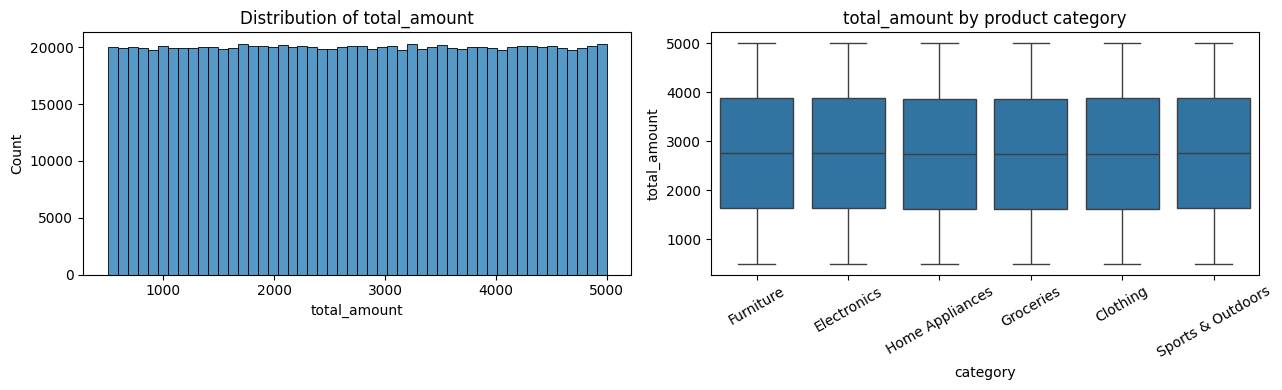

                     mean  median     std
category                                 
Clothing           2751.6  2749.5  1299.8
Electronics        2753.8  2755.4  1300.0
Furniture          2752.9  2752.5  1300.0
Groceries          2749.3  2749.6  1297.7
Home Appliances    2743.6  2740.6  1296.9
Sports & Outdoors  2754.1  2755.5  1299.0
                          count     mean
store_type                              
Large Malls / Complexes  316699  2752.02
Small Stores / Shops     336889  2752.47
Supermarkets             346412  2748.28


In [ ]:
#Distribution plots for total_amount, category-wise boxplots

print(df["total_amount"].describe().round(2))
print("Skew:", round(df["total_amount"].skew(), 3))
print("Kurtosis:", round(df["total_amount"].kurt(), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df["total_amount"], bins=50, ax=ax[0])
ax[0].set_title("Distribution of total_amount")

sns.boxplot(data=df, x="category", y="total_amount", ax=ax[1])
ax[1].set_title("total_amount by product category")
ax[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print(df.groupby("category")["total_amount"].agg(
    ["mean", "median", "std"]
).round(1))

print(df.groupby("store_type")["total_amount"].agg(
    ["count", "mean"]
).round(2))

                 total_amount  campaign_budget  weekday  month  quarter
total_amount            1.000            0.000   -0.000  0.002    0.002
campaign_budget         0.000            1.000    0.008  0.049    0.050
weekday                -0.000            0.008    1.000 -0.003   -0.014
month                   0.002            0.049   -0.003  1.000    0.966
quarter                 0.002            0.050   -0.014  0.966    1.000


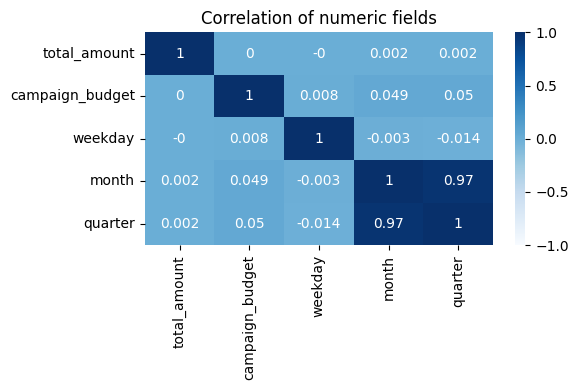

In [ ]:
#correlation checks between numeric fields,

num_cols = ["total_amount", "campaign_budget", "weekday", "month", "quarter"]

corr = df[num_cols].corr().round(3)
print(corr)

plt.figure(figsize=(6, 4))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=-1, vmax=1)
plt.title("Correlation of numeric fields")
plt.tight_layout()
plt.show()

In [ ]:
# Revenue patterns by weekday and month
print(df.groupby("weekday")["total_amount"].agg(
    ["count", "sum"]
).round(0))

print(df.groupby("month")["total_amount"].agg(
    ["count", "sum"]
).round(0))

          count          sum
weekday                     
1        140151  385567124.0
2        140864  387359253.0
3        145925  401178953.0
4        145137  399729367.0
5        143769  396139285.0
6        144578  396891072.0
7        139576  384009540.0
        count          sum
month                     
1       15432   42074800.0
2       68921  189469918.0
3       45027  123914551.0
4       57714  158747404.0
5       80225  220590004.0
6       80674  221196979.0
7      100757  277488251.0
8      102354  281527869.0
9      138685  381041102.0
10     153323  422894156.0
11     134902  371334653.0
12      21986   60594909.0


In [ ]:
#EDA Summary – Key Findings
- Transaction Distribution: 1 million transactions, ranging from ₹500 to ₹4,999.98, with an average value of ₹2,750.87. Skewness is 0.000 and kurtosis is -1.199.
- Category & Store Analysis: Average transaction values are consistent across all product categories and store types (approximately ₹2,750).
- Correlation: Transaction amount has negligible correlation with campaign budget, weekday, month and quarter. Month and quarter show a correlation of 0.966.
- Sales Trends: October recorded the highest volume (153,323 transactions), while January recorded the lowest (15,432).
- Business Insight: Revenue variations are driven more by transaction volume than transaction value. Further analysis should focus on customer behaviour, campaign performance and seasonal trends.

In [ ]:

# ============================================================
# TASK 3: FEATURE ENGINEERING
# ============================================================

# Reference date: latest sales date in the dataset
ref_date = df["sales_date"].max()


# ------------------------------------------------------------
# 1. ROW-LEVEL FEATURES
# ------------------------------------------------------------

# Extract day name
df["day_name"] = df["sales_date"].dt.day_name()

# Weekend indicator (1 = Saturday/Sunday)
# weekday: 1 = Monday ... 7 = Sunday
df["is_weekend"] = df["weekday"].isin([6, 7]).astype(int)

# Campaign indicator (1 = campaign sale)
df["campaign_flag"] = df["campaign_sk"].notna().astype(int)

# Peak season indicator (September to November)
# Assumed peak season; validate using monthly sales analysis
df["peak_season"] = df["month"].isin([9, 10, 11]).astype(int)


# ------------------------------------------------------------
# 2. CUSTOMER-LEVEL FEATURES
# ------------------------------------------------------------

cust = df.groupby("customer_sk").agg(
    first_purchase=("sales_date", "min"),
    last_purchase=("sales_date", "max"),
    order_count=("sales_sk", "count"),
    total_spend=("total_amount", "sum"),
    avg_order_value=("total_amount", "mean"),
    purchase_days=("sales_date", lambda s: s.dt.date.nunique())
)


# ------------------------------------------------------------
# 3. CALCULATE CUSTOMER FEATURES
# ------------------------------------------------------------

# Customer tenure
cust["tenure_days"] = (
    cust["last_purchase"] - cust["first_purchase"]
).dt.days

# Days since last purchase
cust["recency_days"] = (
    ref_date - cust["last_purchase"]
).dt.days

# Average gap between purchases
cust["avg_gap_days"] = np.where(
    cust["order_count"] > 1,
    cust["tenure_days"] / (cust["order_count"] - 1),
    np.nan
)

# Orders per month
# Minimum 30-day denominator for short-tenure customers
cust["orders_per_month"] = (
    cust["order_count"] /
    (cust["tenure_days"].clip(lower=30) / 30)
)

# Average sales records per shopping day
# This is a proxy, not actual basket size
cust["avg_orders_per_purchase_day"] = (
    cust["order_count"] / cust["purchase_days"]
)

# Customer acquisition cohort month
cust["cohort_month"] = (
    cust["first_purchase"].dt.to_period("M")
)


# ------------------------------------------------------------
# 4. CHECK OUTPUT
# ------------------------------------------------------------

print("Total customers with at least one purchase:", len(cust))

print("\nCustomer feature summary:")

display(
    cust[[
        "tenure_days",
        "order_count",
        "recency_days",
        "orders_per_month",
        "avg_orders_per_purchase_day"
    ]].describe().round(2)
)


Total customers with at least one purchase: 99996

Customer feature summary:


,tenure_days,order_count,recency_days,orders_per_month,avg_orders_per_purchase_day
count,99996.00,99996.00,99996.00,99996.00,99996.00
mean,247.81,10.00,42.32,1.24,1.02
std,52.56,3.16,22.98,0.41,0.05
min,0.00,1.00,0.00,0.23,1.00
25%,218.00,8.00,28.00,0.97,1.00
50%,262.00,10.00,39.00,1.20,1.00
75%,287.00,12.00,52.00,1.46,1.00
max,355.00,26.00,323.00,6.23,1.67


Customers acquired by month:
cohort_month
2024-01    14298
2024-02    42558
2024-03    15603
2024-04    12127
2024-05     8496
2024-06     3738
2024-07     1990
2024-08      769
2024-09      319
2024-10       86
2024-11       12
Freq: M, Name: count, dtype: int64


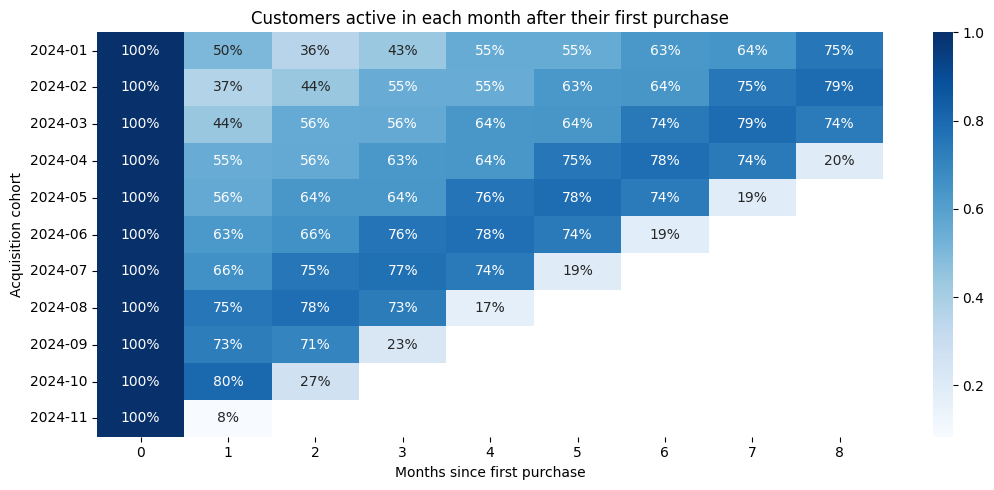


Cohort shape: (11, 12)
Retention shape: (11, 12)

First-month retention:
count    11.0
mean      1.0
std       0.0
min       1.0
25%       1.0
50%       1.0
75%       1.0
max       1.0
Name: 0, dtype: float64

Retention values between 0 and 1: True

New customers by month:
sales_date
2024-01    14298
2024-02    42558
2024-03    15603
2024-04    12127
2024-05     8496
2024-06     3738
2024-07     1990
2024-08      769
2024-09      319
2024-10       86
2024-11       12
Freq: M, Name: count, dtype: int64

Total customers: 99996
February cohort: 42558


In [ ]:

# ============================================================
# TASK 4: COHORT ANALYSIS
# ============================================================

# Prepare customer purchase data
orders = df[["customer_sk", "sales_date"]].merge(
    cust[["cohort_month"]],
    left_on="customer_sk",
    right_index=True
)

# Calculate purchase month
orders["order_month"] = orders["sales_date"].dt.to_period("M")

# Calculate months since first purchase
orders["months_since"] = (
    (orders["order_month"].dt.year - orders["cohort_month"].dt.year) * 12
    + (orders["order_month"].dt.month - orders["cohort_month"].dt.month)
)

# Count active customers
cohort_counts = orders.groupby(
    ["cohort_month", "months_since"]
)["customer_sk"].nunique().unstack()

# Calculate retention percentage
retention = cohort_counts.div(cohort_counts[0], axis=0)

# Visualize the retention heatmap
print("Customers acquired by month:")
print(cust["cohort_month"].value_counts().sort_index())

plt.figure(figsize=(11, 5))

sns.heatmap(
    retention.iloc[:, :9],
    annot=True,
    fmt=".0%",
    cmap="Blues"
)

plt.title("Customers active in each month after their first purchase")
plt.xlabel("Months since first purchase")
plt.ylabel("Acquisition cohort")
plt.tight_layout()
plt.show()

# Delete temporary data
del orders

# Validate cohort output
print("\nCohort shape:", cohort_counts.shape)
print("Retention shape:", retention.shape)

print("\nFirst-month retention:")
print(retention[0].describe())

print(
    "\nRetention values between 0 and 1:",
    retention.stack().between(0, 1).all()
)

# Get each customer's first purchase month
first_purchase = df.groupby("customer_sk")["sales_date"].min()

# Count newly acquired customers by month
cohort_counts_check = (
    first_purchase.dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nNew customers by month:")
print(cohort_counts_check)

print("\nTotal customers:", cohort_counts_check.sum())

# February cohort validation
february = pd.Period("2024-02", freq="M")

if february in cohort_counts_check.index:
    print(
        "February cohort:",
        cohort_counts_check.loc[february]
    )
else:
    print("February cohort not found")


In [ ]:
cust = cust.reset_index()
print(cust.columns.tolist())
print("Customer count:", len(cust))

['customer_sk', 'first_purchase', 'last_purchase', 'order_count', 'total_spend', 'avg_order_value', 'purchase_days', 'tenure_days', 'recency_days', 'orders_per_month', 'avg_basket_size', 'avg_gap_days', 'cohort_month']
Customer count: 99996


In [ ]:

# ============================================================
# TASK 5: CUSTOMER SEGMENTATION
# STEP 5.1: BUILD RFM TABLE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree


# Reset customer_sk from index to column
cust = cust.reset_index(drop=True) if "customer_sk" in cust.columns else cust.reset_index()


# Build RFM table

# Amount    = Total customer spending
# Frequency = Number of sales records
# Recency   = Days since last purchase

rfm = cust[
    ["total_spend", "order_count", "recency_days"]
].rename(
    columns={
        "total_spend": "Amount",
        "order_count": "Frequency",
        "recency_days": "Recency"
    }
).copy()


# Display RFM summary

print("RFM shape:", rfm.shape)

display(rfm.describe().round(1))

print("\nFirst five customer records:")
display(rfm.head())


RFM shape: (99996, 3)


,Amount,Frequency,Recency
count,99996.0,99996.0,99996.0
mean,27509.8,10.0,42.3
std,9618.3,3.2,23.0
min,598.6,1.0,0.0
25%,20670.8,8.0,28.0
50%,26863.8,10.0,39.0
75%,33623.5,12.0,52.0
max,83865.1,26.0,323.0



First five customer records:


,Amount,Frequency,Recency
0,26145.35,13,30
1,15856.65,8,105
2,26372.71,8,49
3,13134.21,4,48
4,23735.77,9,41


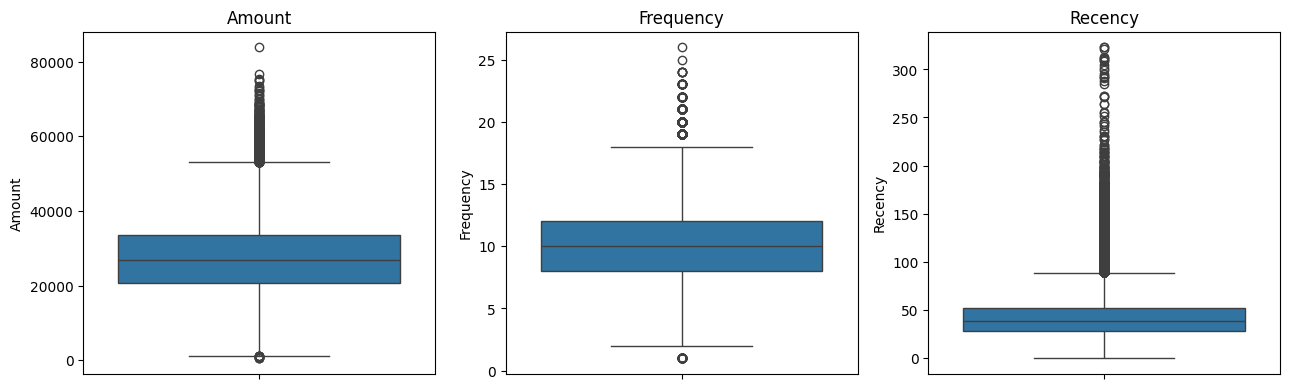

Amount statistical outliers: 0
Frequency statistical outliers: 0
Recency statistical outliers: 80


In [ ]:

# ============================================================
# STEP 5.2: OUTLIER ANALYSIS
# ============================================================

# Visualize the distribution of each RFM feature

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

for a, col in zip(ax, ["Amount", "Frequency", "Recency"]):
    sns.boxplot(y=rfm[col], ax=a)
    a.set_title(col)

plt.tight_layout()
plt.show()


# 5th and 95th percentile rule with 1.5 x spread

def outlier_mask(s):
    q1 = s.quantile(0.05)
    q3 = s.quantile(0.95)
    iqr = q3 - q1

    return (
        (s < q1 - 1.5 * iqr) |
        (s > q3 + 1.5 * iqr)
    )


# Count statistical outliers

for col in ["Amount", "Frequency", "Recency"]:
    print(
        col,
        "statistical outliers:",
        int(outlier_mask(rfm[col]).sum())
    )


# Retain high-recency customers.
# They may be genuine lapsing customers, not data errors.


In [ ]:

# ============================================================
# STEP 5.3: STANDARDIZE RFM FEATURES
# ============================================================

# Standardize the RFM features

scaler = StandardScaler()

X = scaler.fit_transform(rfm)

print("\nFirst three scaled rows:")

display(
    pd.DataFrame(
        X,
        columns=rfm.columns,
        index=rfm.index
    ).head(3).round(2)
)


# Sensitivity check: compare K-Means with and without
# the high-recency outliers

keep = ~outlier_mask(rfm["Recency"]).values


# K-Means model using all customers

with_all = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
).fit(X)


# K-Means model excluding high-recency outliers

without = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
).fit(X[keep])


# Compare the two models on common customers

agreement = adjusted_rand_score(
    with_all.predict(X[keep]),
    without.predict(X[keep])
)

print(
    "Agreement between models:",
    round(agreement, 3)
)



First three scaled rows:


,Amount,Frequency,Recency
0,-0.14,0.95,-0.54
1,-1.21,-0.63,2.73
2,-0.12,-0.63,0.29


Agreement between models: 0.977


First 10 cluster labels:
[2 3 1 1 1 2 1 2 1 2]

K selection results:


,k,inertia,silhouette
0,2,170855,0.377
1,3,127014,0.342
2,4,100233,0.312
3,5,85276,0.310
4,6,74078,0.288
5,7,66636,0.279
6,8,60441,0.275


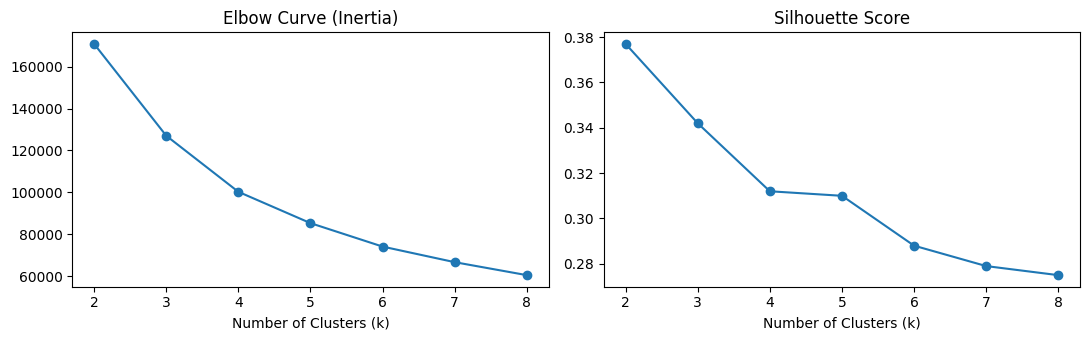

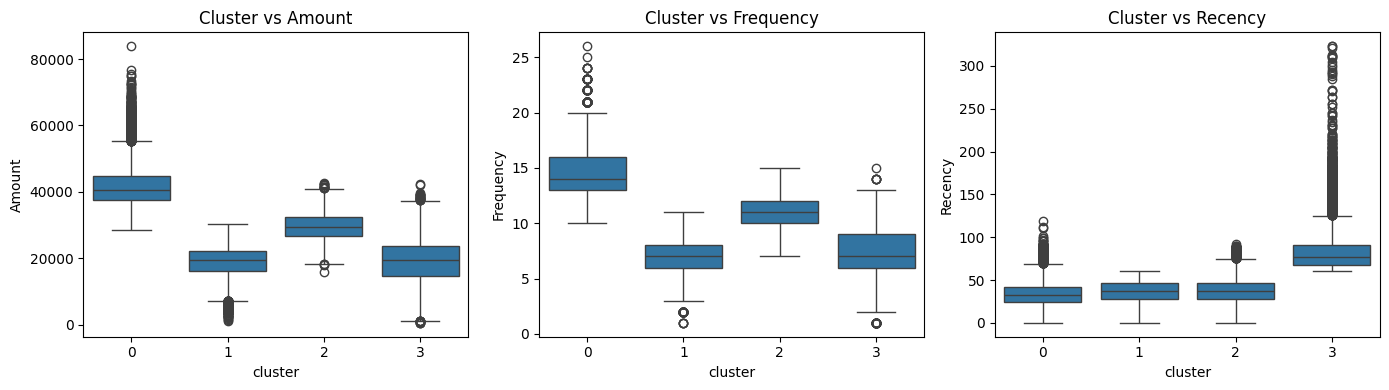


Final K-Means cluster profile:


,customers,recency,frequency,spend,name
cluster,,,,,
0,18660,33.2,14.6,41740.9,Champions
2,39642,37.1,10.8,29697.6,Loyal Regulars
3,12870,84.3,7.2,19380.1,Lapsing Buyers
1,28824,36.7,7.2,18918.1,Occasional Buyers


In [ ]:

# ============================================================
# STEP 5.4: K-MEANS CLUSTERING
# ============================================================

# First fit an initial K-Means model with K=4

kmeans = KMeans(
    n_clusters=4,
    max_iter=50,
    random_state=42,
    n_init=10
).fit(X)

print("First 10 cluster labels:")
print(kmeans.labels_[:10])


# Find an appropriate K using Elbow and Silhouette

rows = []

for k in range(2, 9):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    ).fit(X)

    sil = silhouette_score(
        X,
        km.labels_,
        sample_size=10000,
        random_state=42
    )

    rows.append((
        k,
        round(km.inertia_),
        round(sil, 3)
    ))


k_table = pd.DataFrame(
    rows,
    columns=["k", "inertia", "silhouette"]
)

print("\nK selection results:")
display(k_table)


# Plot Elbow and Silhouette curves

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

ax[0].plot(
    k_table["k"],
    k_table["inertia"],
    marker="o"
)

ax[0].set_title("Elbow Curve (Inertia)")
ax[0].set_xlabel("Number of Clusters (k)")


ax[1].plot(
    k_table["k"],
    k_table["silhouette"],
    marker="o"
)

ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of Clusters (k)")

plt.tight_layout()
plt.show()


# Final model: K=4, as justified in the project document

km = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
).fit(X)

cust["cluster"] = km.labels_

rfm["cluster"] = km.labels_


# Compare clusters against the three RFM features

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

for a, col in zip(ax, ["Amount", "Frequency", "Recency"]):

    sns.boxplot(
        x="cluster",
        y=col,
        data=rfm,
        ax=a
    )

    a.set_title(f"Cluster vs {col}")

plt.tight_layout()
plt.show()


# Profile each cluster

profile = cust.groupby("cluster").agg(
    customers=("order_count", "size"),
    recency=("recency_days", "mean"),
    frequency=("order_count", "mean"),
    spend=("total_spend", "mean")
).round(1)


# Assign business-friendly names based on actual profiles

names = {}

names[profile["spend"].idxmax()] = "Champions"

rest = profile.drop(index=list(names))

names[rest["recency"].idxmax()] = "Lapsing Buyers"

rest = profile.drop(index=list(names))

names[rest["spend"].idxmax()] = "Loyal Regulars"

for c in profile.index:
    names.setdefault(c, "Occasional Buyers")


cust["cluster_name"] = cust["cluster"].map(names)

profile["name"] = profile.index.map(names)


print("\nFinal K-Means cluster profile:")

display(profile.sort_values("spend", ascending=False))


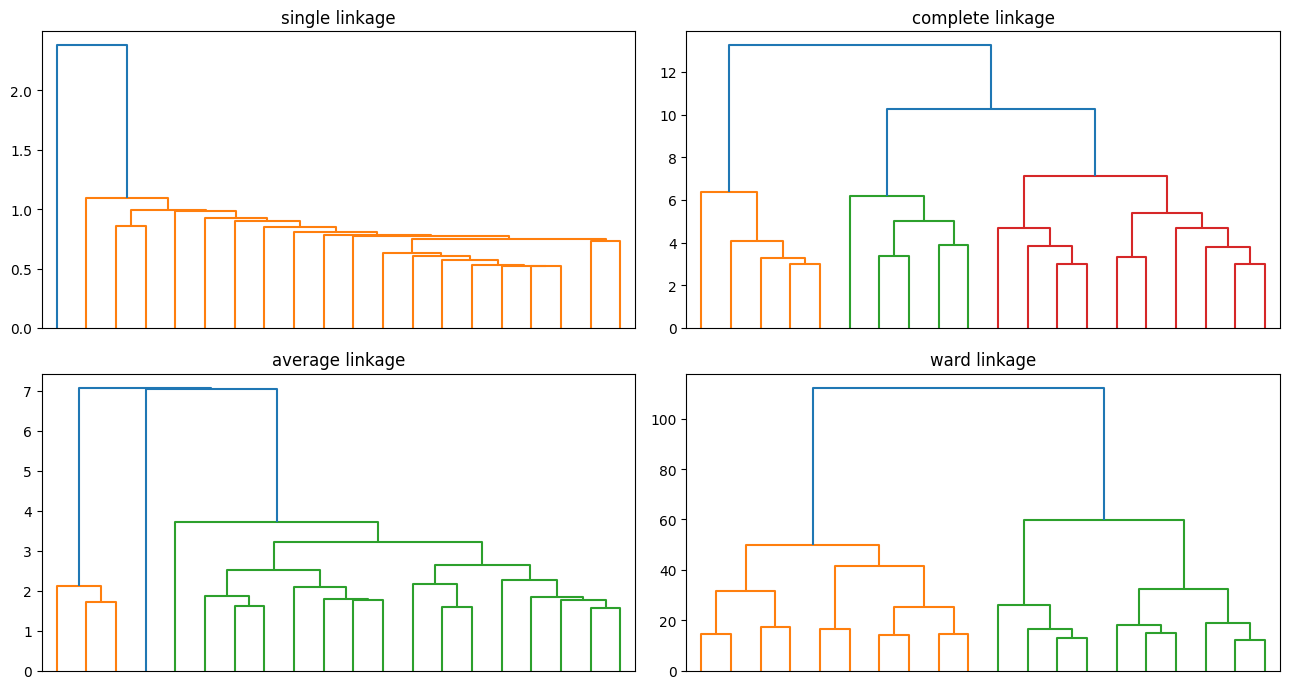

single    cluster sizes: [4996, 2, 1, 1]
complete  cluster sizes: [1118, 675, 3013, 194]
average   cluster sizes: [4989, 9, 1, 1]
ward      cluster sizes: [1322, 1087, 1419, 1172]


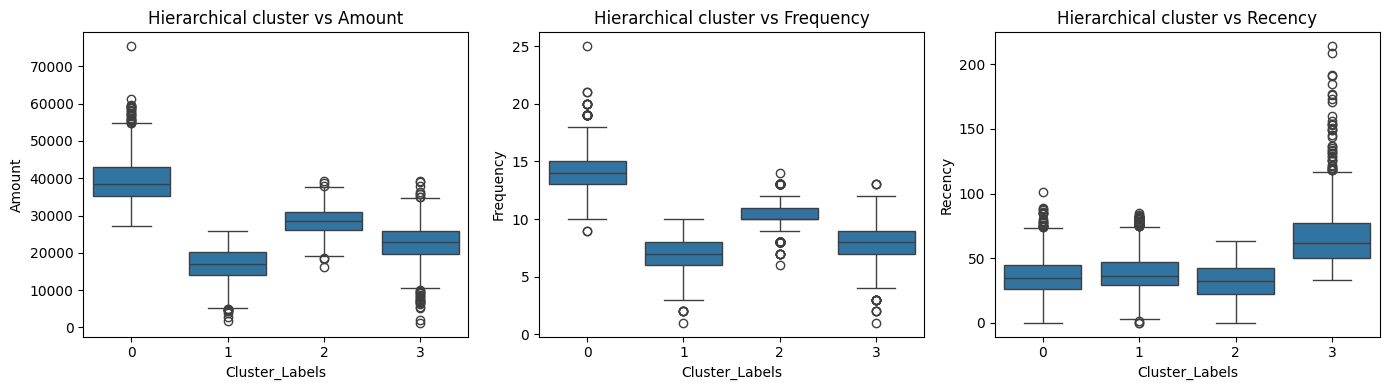


Hierarchical cluster profile:


,customers,amount,frequency,recency
Cluster_Labels,,,,
0,1322,39494.3,13.9,35.7
1,1087,16913.9,6.6,38.7
2,1419,28457.7,10.4,31.0
3,1172,22687.1,8.2,67.1


Agreement with K-Means (Adjusted Rand Index): 0.466


In [ ]:

# ============================================================
# STEP 5.5: HIERARCHICAL CLUSTERING
# ============================================================

# Use a sample of 5,000 customers because hierarchical
# clustering requires a large pairwise distance calculation.

sample = rfm[
    ["Amount", "Frequency", "Recency"]
].sample(
    n=5000,
    random_state=42
).copy()


# Scale the sample separately

Xs = StandardScaler().fit_transform(sample)


# Compare four linkage methods using dendrograms

fig, axes = plt.subplots(2, 2, figsize=(13, 7))

for ax, method in zip(
    axes.ravel(),
    ["single", "complete", "average", "ward"]
):

    Z = linkage(
        Xs,
        method=method,
        metric="euclidean"
    )

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=20,
        no_labels=True,
        ax=ax
    )

    ax.set_title(f"{method} linkage")

plt.tight_layout()
plt.show()


# Compare cluster sizes for all four linkage methods

for method in ["single", "complete", "average", "ward"]:

    labels = cut_tree(
        linkage(Xs, method=method),
        n_clusters=4
    ).reshape(-1)

    print(
        f"{method:9s} cluster sizes:",
        np.bincount(labels).tolist()
    )


# Ward linkage gives balanced groups

Z_ward = linkage(
    Xs,
    method="ward",
    metric="euclidean"
)

labels_h = cut_tree(
    Z_ward,
    n_clusters=4
).reshape(-1)

sample["Cluster_Labels"] = labels_h


# Plot hierarchical cluster profiles

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

for a, col in zip(
    ax,
    ["Amount", "Frequency", "Recency"]
):

    sns.boxplot(
        x="Cluster_Labels",
        y=col,
        data=sample,
        ax=a
    )

    a.set_title(f"Hierarchical cluster vs {col}")

plt.tight_layout()
plt.show()


# Profile hierarchical clusters

hierarchical_profile = sample.groupby(
    "Cluster_Labels"
).agg(
    customers=("Amount", "size"),
    amount=("Amount", "mean"),
    frequency=("Frequency", "mean"),
    recency=("Recency", "mean")
).round(1)

print("\nHierarchical cluster profile:")
display(hierarchical_profile)


# Compare K-Means and Ward clustering on the same 5,000 customers

kmeans_labels = cust.loc[
    sample.index,
    "cluster"
].values

ari = adjusted_rand_score(
    kmeans_labels,
    labels_h
)

print(
    "Agreement with K-Means (Adjusted Rand Index):",
    round(ari, 3)
)


In [ ]:

# ============================================================
# STEP 5.6: FINAL VALIDATION AND EXPORT
# ============================================================

print("\nFinal validation")

# Check total and unique customers

print("Total customers:", len(cust))
print("Unique customers:", cust["customer_sk"].nunique())

# Check cluster counts

print("K-Means clusters:", cust["cluster"].nunique())
print("Named segments:", cust["cluster_name"].nunique())


# Customer counts by segment

print("\nCustomer counts by segment:")
print(cust["cluster_name"].value_counts())


# Validate the results

assert len(cust) == 99996

assert cust["customer_sk"].nunique() == 99996

assert cust["cluster"].notna().all()

assert cust["cluster_name"].notna().all()

assert cust["cluster_name"].nunique() == 4

assert cust["cluster"].nunique() == 4


# Export customer segmentation results

cust.to_csv(
    "customer_segmentation.csv",
    index=False
)


# Export K-Means cluster profile

profile.to_csv(
    "kmeans_cluster_profile.csv"
)


# Export hierarchical cluster profile

hierarchical_profile.to_csv(
    "hierarchical_cluster_profile.csv"
)


# Export K selection results

k_table.to_csv(
    "kmeans_model_selection.csv",
    index=False
)


print("\nTask 5 completed. Output files exported.")



Final validation
Total customers: 99996
Unique customers: 99996
K-Means clusters: 4
Named segments: 4

Customer counts by segment:
cluster_name
Loyal Regulars       39642
Occasional Buyers    28824
Champions            18660
Lapsing Buyers       12870
Name: count, dtype: int64

Task 5 completed. Output files exported.


In [ ]:

# ============================================================
# TASK 6: CHURN RISK ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. CHURN-RISK FLAG
# ------------------------------------------------------------

# Rule:
# Customer is at risk when recency is more than
# 2 times their usual purchase gap.

cust["churn_risk"] = np.where(
    cust["order_count"] < 2,
    "Insufficient history",
    np.where(
        cust["recency_days"] > 2 * cust["avg_gap_days"],
        "High Risk",
        "Active"
    )
)

print("Churn Risk Distribution:")
print(cust["churn_risk"].value_counts())

print("\nChurn Risk Percentage:")
print(
    (cust["churn_risk"].value_counts(normalize=True) * 100)
    .round(2)
)


# ------------------------------------------------------------
# 2. HOLDOUT VALIDATION
# ------------------------------------------------------------

# Build the churn-risk flag using data up to
# 30 September 2024, then check future purchases.

cutoff = pd.Timestamp("2024-09-30 23:59:59")

before = df[df["sales_date"] <= cutoff]

after = df[df["sales_date"] > cutoff]


# Calculate customer purchase history before cutoff

h = before.groupby("customer_sk").agg(
    first=("sales_date", "min"),
    last=("sales_date", "max"),
    n=("sales_sk", "count")
)


# Retain customers with at least two sales records

h = h[h["n"] >= 2].copy()


# Calculate average purchase gap

h["gap"] = (
    (h["last"] - h["first"]).dt.days /
    (h["n"] - 1)
)


# Calculate recency as of cutoff date

h["recency"] = (
    cutoff - h["last"]
).dt.days


# Identify high-risk customers

h["flag"] = (
    h["recency"] > 2 * h["gap"]
)


# Check whether customers made any purchase after cutoff

h["lapsed"] = ~h.index.isin(
    set(after["customer_sk"])
)


# Compare predicted risk with actual future inactivity

print("\nHoldout Validation Results:")

print(
    h.groupby("flag")["lapsed"].agg(
        customers="size",
        lapse_rate="mean"
    ).round(3)
)


# ------------------------------------------------------------
# 3. CROSS-CHECK EXISTING CUSTOMER LABELS
# ------------------------------------------------------------

# Compare churn-risk flags with existing customer labels
# from Dim_Customers.

labels = df.drop_duplicates(
    "customer_sk"
).set_index(
    "customer_sk"
)["customer_segment"]


# Map existing customer labels to customer summary

cust["segment_label"] = cust["customer_sk"].map(labels)


# Calculate high-risk percentage by customer segment

print("\nHigh-Risk Percentage by Customer Segment:")

print(
    cust.groupby("segment_label")["churn_risk"].apply(
        lambda s: (s == "High Risk").mean()
    ).round(3)
)


# Display customer segment counts

print("\nCustomer Segment Distribution:")

print(cust["segment_label"].value_counts())


print("\nTask 6 analysis completed.")


Churn Risk Distribution:
churn_risk
Active                  75806
High Risk               24142
Insufficient history       48
Name: count, dtype: int64

Churn Risk Percentage:
churn_risk
Active                  75.81
High Risk               24.14
Insufficient history     0.05
Name: proportion, dtype: float64

Holdout Validation Results:
       customers  lapse_rate
flag                        
False      90801       0.045
True        8422       0.042

High-Risk Percentage by Customer Segment:
segment_label
Budget Shopper        0.242
Churn Risk            0.241
Deal Seeker           0.240
First-time Buyer      0.232
High Value            0.244
In-Store Regular      0.246
Loyal Customer        0.240
Occasional Shopper    0.246
Online Shopper        0.241
Premium Shopper       0.243
Name: churn_risk, dtype: float64

Customer Segment Distribution:
segment_label
Deal Seeker           10082
Occasional Shopper    10049
Online Shopper        10048
High Value            10034
Loyal Customer   

In [ ]:

# Task 7: Hypothesis Testing – Campaign vs Outside-Campaign Sales Amount
# Statistical Test: Welch's Independent Two-Sample T-Test

from scipy import stats
from sqlalchemy import text
import pandas as pd
import numpy as np

# Step 1: Get campaign date ranges using date dimension
camp = pd.read_sql(
    text("""
        SELECT
            c.campaign_sk,
            start_date.full_date AS start_date,
            end_date.full_date AS end_date
        FROM dim_campaigns c
        LEFT JOIN dim_dates start_date
            ON c.start_date_sk = start_date.date_sk
        LEFT JOIN dim_dates end_date
            ON c.end_date_sk = end_date.date_sk
    """),
    engine
)

# Convert text dates into datetime
camp["start_date"] = pd.to_datetime(camp["start_date"])
camp["end_date"] = pd.to_datetime(camp["end_date"])

# Check campaign date mapping
print("Total campaigns:", len(camp))
print("Missing start dates:", camp["start_date"].isna().sum())
print("Missing end dates:", camp["end_date"].isna().sum())


# Step 2: Compare sales inside and outside campaign windows
m = df[["campaign_sk", "sales_date", "total_amount"]].merge(
    camp, on="campaign_sk"
)

m["inside"] = (
    (m["sales_date"] >= m["start_date"]) &
    (m["sales_date"] < m["end_date"] + pd.Timedelta(days=1))
)

inside = m.loc[m["inside"], "total_amount"].dropna()
outside = m.loc[~m["inside"], "total_amount"].dropna()


# Step 3: Welch's t-test
t = stats.ttest_ind(
    inside,
    outside,
    equal_var=False
)

diff = inside.mean() - outside.mean()

# Standard error
se = np.sqrt(
    inside.var(ddof=1) / len(inside) +
    outside.var(ddof=1) / len(outside)
)

# Welch degrees of freedom
v1 = inside.var(ddof=1) / len(inside)
v2 = outside.var(ddof=1) / len(outside)

df_welch = (v1 + v2) ** 2 / (
    v1**2 / (len(inside) - 1) +
    v2**2 / (len(outside) - 1)
)

critical_value = stats.t.ppf(0.975, df_welch)

ci_lower = diff - critical_value * se
ci_upper = diff + critical_value * se


# Step 4: Display results
print("\n--- Hypothesis Testing Results ---")

print("Inside campaign window:")
print("Count:", len(inside))
print("Mean:", round(inside.mean(), 2))

print("\nOutside campaign window:")
print("Count:", len(outside))
print("Mean:", round(outside.mean(), 2))

print("\nWelch t-statistic:", round(t.statistic, 3))
print("P-value:", t.pvalue)
print("Mean difference:", round(diff, 2))

print("95% Confidence Interval:",
      round(ci_lower, 2), "to", round(ci_upper, 2))


# Step 5: Interpretation
if t.pvalue < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("The average sales amounts are significantly different.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a significant difference.")


Total campaigns: 50
Missing start dates: 0
Missing end dates: 0

--- Hypothesis Testing Results ---
Inside campaign window:
Count: 394920
Mean: 2751.97

Outside campaign window:
Count: 605080
Mean: 2750.16

Welch t-statistic: 0.684
P-value: 0.4939812702260964
Mean difference: 1.82
95% Confidence Interval: -3.39 to 7.03

Decision: Fail to reject the null hypothesis.
There is insufficient evidence of a significant difference.


49 complete weeks: 2024-01-21 to 2024-12-22

FORECAST MODEL COMPARISON
                model  MAPE all weeks %  MAPE before Nov %  MAPE last 6 weeks %
    Last week (naive)              17.8               10.4                 56.4
4-week moving average              36.8               11.8                166.3
Simple exp. smoothing              29.5               15.2                103.6
          Damped Holt              28.7               12.2                113.8

Best forecasting model: Last week (naive)

FORECAST FOR NEXT FOUR WEEKS
2024-12-29    10273719.55
2025-01-05    10273719.55
2025-01-12    10273719.55
2025-01-19    10273719.55
Freq: W-SUN, dtype: float64

Total four-week revenue forecast: 41094878.2


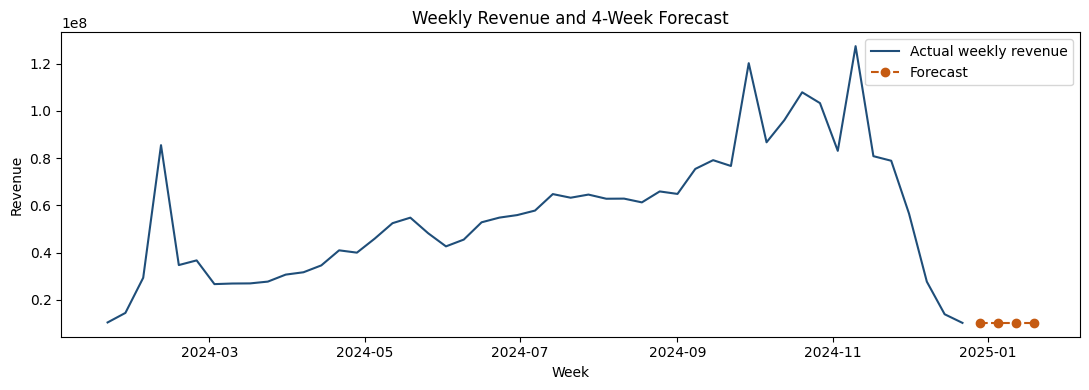


TASK 8 - FINAL SUMMARY
----------------------
Best model: Last week (naive)
Overall MAPE: 17.8 %
Four-week revenue forecast: 41094878.2
Forecast confidence: Low


In [ ]:

# ============================================================
# TASK 8: REVENUE FORECASTING
# Walk-Forward Validation and Model Comparison
# ============================================================

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)
from statsmodels.tools.sm_exceptions import ConvergenceWarning
import warnings

warnings.simplefilter("ignore", ConvergenceWarning)


# 1. WEEKLY REVENUE
# Complete weeks only: remove first 2 partial weeks and last partial week

weekly = (
    df.set_index("sales_date")["total_amount"]
    .resample("W-SUN")
    .sum()
    .iloc[2:-1]
)

print(
    len(weekly),
    "complete weeks:",
    weekly.index[0].date(),
    "to",
    weekly.index[-1].date()
)


# 2. MAPE FUNCTION

def mape(actual, forecast):
    return float(
        np.mean(np.abs((actual - forecast) / actual)) * 100
    )


# 3. WALK-FORWARD VALIDATION

actual, naive, ma4, ses, holt = [], [], [], [], []

for i in range(12, len(weekly)):

    hist = weekly.iloc[:i]

    actual.append(weekly.iloc[i])

    # Model 1: Last week's revenue
    naive.append(hist.iloc[-1])

    # Model 2: Four-week moving average
    ma4.append(hist.iloc[-4:].mean())

    # Model 3: Simple exponential smoothing
    ses.append(
        SimpleExpSmoothing(
            hist,
            initialization_method="estimated"
        ).fit().forecast(1).iloc[0]
    )

    # Model 4: Damped Holt
    holt.append(
        ExponentialSmoothing(
            hist,
            trend="add",
            damped_trend=True,
            initialization_method="estimated"
        ).fit().forecast(1).iloc[0]
    )


# 4. MODEL COMPARISON USING MAPE

actual = np.array(actual)

results = pd.DataFrame({
    "model": [
        "Last week (naive)",
        "4-week moving average",
        "Simple exp. smoothing",
        "Damped Holt"
    ],

    "MAPE all weeks %": [
        mape(actual, np.array(f))
        for f in (naive, ma4, ses, holt)
    ],

    "MAPE before Nov %": [
        mape(actual[:-6], np.array(f)[:-6])
        for f in (naive, ma4, ses, holt)
    ],

    "MAPE last 6 weeks %": [
        mape(actual[-6:], np.array(f)[-6:])
        for f in (naive, ma4, ses, holt)
    ]
}).round(1)

print("\nFORECAST MODEL COMPARISON")
print(results.to_string(index=False))


# 5. SELECT BEST MODEL

best_model = results.loc[
    results["MAPE all weeks %"].idxmin(), "model"
]

print("\nBest forecasting model:", best_model)


# 6. FORECAST NEXT FOUR WEEKS USING BEST MODEL

next_weeks = pd.date_range(
    weekly.index[-1] + pd.Timedelta(weeks=1),
    periods=4,
    freq="W-SUN"
)

if best_model == "Last week (naive)":

    next_values = [weekly.iloc[-1]] * 4

elif best_model == "4-week moving average":

    next_values = [weekly.iloc[-4:].mean()] * 4

elif best_model == "Simple exp. smoothing":

    fitted = SimpleExpSmoothing(
        weekly,
        initialization_method="estimated"
    ).fit()

    next_values = fitted.forecast(4).values

else:

    fitted = ExponentialSmoothing(
        weekly,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    ).fit()

    next_values = fitted.forecast(4).values


next_forecast = pd.Series(
    next_values,
    index=next_weeks
)

print("\nFORECAST FOR NEXT FOUR WEEKS")
print(next_forecast.round(2))

print(
    "\nTotal four-week revenue forecast:",
    round(next_forecast.sum(), 2)
)


# 7. VISUALIZE ACTUAL REVENUE AND FORECAST

plt.figure(figsize=(11, 4))

plt.plot(
    weekly.index,
    weekly.values,
    label="Actual weekly revenue",
    color="#1F4E79"
)

plt.plot(
    next_forecast.index,
    next_forecast.values,
    "o--",
    color="#C55A11",
    label="Forecast"
)

plt.title("Weekly Revenue and 4-Week Forecast")
plt.xlabel("Week")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()


# 8. FINAL BUSINESS SUMMARY

print("\nTASK 8 - FINAL SUMMARY")
print("----------------------")

print("Best model:", best_model)

print(
    "Overall MAPE:",
    results.loc[
        results["model"] == best_model,
        "MAPE all weeks %"
    ].iloc[0],
    "%"
)

print(
    "Four-week revenue forecast:",
    round(next_forecast.sum(), 2)
)

print("Forecast confidence: Low")


In [ ]:

# ============================================================
# TASK 9: PRODUCT AFFINITY ANALYSIS
# Apriori Association Rules
# ============================================================

import warnings
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules

# Suppress Jupyter datetime deprecation warnings
warnings.filterwarnings(
    "ignore",
    message=".*utcnow.*",
    category=DeprecationWarning
)


# 1. CREATE CUSTOMER-DAY BASKETS
# Group products purchased by the same customer on the same day

df["sales_date"] = pd.to_datetime(df["sales_date"])
df["day"] = df["sales_date"].dt.date

baskets = (
    df.groupby(["customer_sk", "day"])["product_sk"]
    .agg(lambda s: sorted(set(s.dropna())))
)

multi = baskets[baskets.apply(len) > 1]

print("Total customer-day baskets:", len(baskets))
print("Baskets with 2 or more products:", len(multi))
print(
    "Percentage of multi-product baskets:",
    round(len(multi) / len(baskets) * 100, 2), "%"
)


# 2. CREATE ONE-HOT ENCODED BASKET MATRIX

onehot = pd.DataFrame(
    False,
    index=range(len(multi)),
    columns=sorted(df["product_sk"].dropna().unique())
)

for i, items in enumerate(multi):
    onehot.loc[i, items] = True

print("\nBasket matrix shape:", onehot.shape)


# 3. TEST DIFFERENT SUPPORT THRESHOLDS

print("\nFREQUENT PAIR COMPARISON")

for support in (0.001, 0.0003, 0.0002):

    freq_test = apriori(
        onehot,
        min_support=support,
        use_colnames=True,
        max_len=2
    )

    pair_count = freq_test["itemsets"].apply(len).eq(2).sum()

    print(
        "Minimum support:", support,
        "| Frequent pairs:", int(pair_count)
    )


# 4. GENERATE FREQUENT ITEMSETS

freq = apriori(
    onehot,
    min_support=0.0003,
    use_colnames=True,
    max_len=2
)

print("\nFrequent itemsets found:", len(freq))

print(
    "Frequent product pairs:",
    int(freq["itemsets"].apply(len).eq(2).sum())
)


# 5. GENERATE ASSOCIATION RULES

if not freq.empty and freq["itemsets"].apply(len).eq(2).any():

    rules = association_rules(
        freq,
        metric="lift",
        min_threshold=1.0
    )

else:
    rules = pd.DataFrame()


# 6. DISPLAY TOP 5 PRODUCT ASSOCIATION RULES

if not rules.empty:

    top_rules = rules[
        ["antecedents", "consequents",
         "support", "confidence", "lift"]
    ].sort_values(
        "lift", ascending=False
    ).head(5).copy()

    # Convert product sets into readable product IDs
    top_rules["antecedents"] = top_rules["antecedents"].apply(
        lambda x: ", ".join(map(str, sorted(x)))
    )

    top_rules["consequents"] = top_rules["consequents"].apply(
        lambda x: ", ".join(map(str, sorted(x)))
    )

    top_rules = top_rules.round(3)

    print("\nTOP 5 PRODUCT ASSOCIATION RULES")
    print(top_rules.to_string(index=False))

else:
    print("\nNo association rules found at this support threshold.")


# 7. BUSINESS INTERPRETATION

if not rules.empty:

    best_rule = rules.sort_values(
        "lift", ascending=False
    ).iloc[0]

    print("\nTASK 9 - BUSINESS SUMMARY")
    print("------------------------")

    print(
        "Top associated products:",
        sorted(best_rule["antecedents"]),
        "->",
        sorted(best_rule["consequents"])
    )

    print("Support:", round(best_rule["support"], 4))
    print("Confidence:", round(best_rule["confidence"], 4))
    print("Lift:", round(best_rule["lift"], 3))

    if best_rule["lift"] > 1:
        print(
            "Interpretation: These products occur together more "
            "often than expected by chance."
        )

    print(
        "Business opportunity: Consider product bundles, "
        "cross-selling, and product recommendations."
    )

else:
    print("\nNo business recommendation can be generated.")


Total customer-day baskets: 981847
Baskets with 2 or more products: 17817
Percentage of multi-product baskets: 1.81 %

Basket matrix shape: (17817, 210)

FREQUENT PAIR COMPARISON
Minimum support: 0.001 | Frequent pairs: 0
Minimum support: 0.0003 | Frequent pairs: 6
Minimum support: 0.0002 | Frequent pairs: 245

Frequent itemsets found: 216
Frequent product pairs: 6

TOP 5 PRODUCT ASSOCIATION RULES
antecedents consequents  support  confidence  lift
        131         143      0.0       0.041 4.193
        143         131      0.0       0.040 4.193
         65          72      0.0       0.039 3.654
         72          65      0.0       0.032 3.654
         40         159      0.0       0.041 3.554

TASK 9 - BUSINESS SUMMARY
------------------------
Top associated products: [131] -> [143]
Support: 0.0004
Confidence: 0.0414
Lift: 4.193
Interpretation: These products occur together more often than expected by chance.
Business opportunity: Consider product bundles, cross-selling, and produ

In [ ]:
!pip install pandas numpy sqlalchemy pymysql scikit-learn statsmodels

In [ ]:
import os
from google.colab import userdata

os.environ["TIDB_HOST"] = userdata.get("TIDB_HOST")
os.environ["TIDB_USER"] = userdata.get("TIDB_USER")
os.environ["TIDB_PASSWORD"] = userdata.get("TIDB_PASSWORD")
os.environ["TIDB_DB"] = "project"

print("Database credentials loaded.")

Database credentials loaded.


In [ ]:

%%writefile pipeline.py

import os
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sqlalchemy import create_engine, URL

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing,
    ExponentialSmoothing
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. SETUP AND LOGGING
# ============================================================

Path("output").mkdir(exist_ok=True)

logging.basicConfig(
    filename="output/pipeline.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    filemode="w"
)

def log(message):
    print(message)
    logging.info(message)

log("RETAIL ANALYTICS PIPELINE STARTED")

# ============================================================
# 2. CONNECT TO TIDB CLOUD
# ============================================================

required_variables = [
    "TIDB_HOST",
    "TIDB_USER",
    "TIDB_PASSWORD",
    "TIDB_DB"
]

for variable in required_variables:
    if not os.environ.get(variable):
        raise ValueError(f"Missing environment variable: {variable}")

connection_url = URL.create(
    drivername="mysql+pymysql",
    username=os.environ["TIDB_USER"],
    password=os.environ["TIDB_PASSWORD"],
    host=os.environ["TIDB_HOST"],
    port=4000,
    database=os.environ["TIDB_DB"]
)

engine = create_engine(
    connection_url,
    connect_args={"ssl": {}}
)

log("Connected to TiDB Cloud")

# ============================================================
# 3. LOAD SALES DATA
# ============================================================

query = """
SELECT
    sales_sk,
    sales_id,
    customer_sk,
    product_sk,
    store_sk,
    salesperson_sk,
    campaign_sk,
    sales_date,
    total_amount
FROM fact_sales_normalized
"""

chunks = pd.read_sql_query(
    query,
    engine,
    chunksize=100000
)

df = pd.concat(chunks, ignore_index=True)

df["sales_date"] = pd.to_datetime(
    df["sales_date"],
    errors="coerce"
)

df["total_amount"] = pd.to_numeric(
    df["total_amount"],
    errors="coerce"
)

df = df.dropna(
    subset=["customer_sk", "sales_date", "total_amount"]
)

log(f"Sales records loaded: {len(df):,}")
log(f"Unique customers: {df['customer_sk'].nunique():,}")

# ============================================================
# 4. FEATURE ENGINEERING
# ============================================================

ref_date = df["sales_date"].max()

df["day_name"] = df["sales_date"].dt.day_name()

# Monday = 1 and Sunday = 7
df["weekday"] = df["sales_date"].dt.weekday + 1

df["month"] = df["sales_date"].dt.month

df["is_weekend"] = (
    df["weekday"].isin([6, 7]).astype(int)
)

df["campaign_flag"] = (
    df["campaign_sk"].notna().astype(int)
)

# September to November treated as the assumed peak season
df["peak_season"] = (
    df["month"].isin([9, 10, 11]).astype(int)
)

cust = df.groupby("customer_sk").agg(
    first_purchase=("sales_date", "min"),
    last_purchase=("sales_date", "max"),
    order_count=("sales_sk", "count"),
    total_spend=("total_amount", "sum"),
    avg_order_value=("total_amount", "mean"),
    purchase_days=(
        "sales_date",
        lambda s: s.dt.date.nunique()
    )
)

cust["tenure_days"] = (
    cust["last_purchase"] - cust["first_purchase"]
).dt.days

cust["recency_days"] = (
    ref_date - cust["last_purchase"]
).dt.days

cust["avg_gap_days"] = np.where(
    cust["order_count"] > 1,
    cust["tenure_days"] / (cust["order_count"] - 1),
    np.nan
)

cust["orders_per_month"] = (
    cust["order_count"] /
    (cust["tenure_days"].clip(lower=30) / 30)
)

cust["avg_orders_per_purchase_day"] = (
    cust["order_count"] / cust["purchase_days"]
)

cust["cohort_month"] = (
    cust["first_purchase"].dt.to_period("M").astype(str)
)

log(f"Customer features created: {len(cust):,}")

# ============================================================
# 5. CUSTOMER SEGMENTATION USING K-MEANS
# ============================================================

features = [
    "total_spend",
    "order_count",
    "recency_days"
]

X = cust[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cust["cluster"] = kmeans.fit_predict(X_scaled)

# Create business-friendly segment names
profiles = cust.groupby("cluster").agg(
    customers=("total_spend", "size"),
    avg_spend=("total_spend", "mean"),
    avg_frequency=("order_count", "mean"),
    avg_recency=("recency_days", "mean")
)

remaining = list(profiles.index)

# Highest-spending cluster
champions = profiles["avg_spend"].idxmax()
remaining.remove(champions)

# Highest-frequency cluster among remaining
loyal = profiles.loc[remaining, "avg_frequency"].idxmax()
remaining.remove(loyal)

# Highest-recency cluster among remaining
lapsing = profiles.loc[remaining, "avg_recency"].idxmax()
remaining.remove(lapsing)

occasional = remaining[0]

segment_names = {
    champions: "Champions",
    loyal: "Loyal Regulars",
    lapsing: "Lapsing Buyers",
    occasional: "Occasional Buyers"
}

cust["cluster_name"] = cust["cluster"].map(segment_names)

log("K-Means segmentation completed")
log("Segment distribution:")
log(str(cust["cluster_name"].value_counts()))

# ============================================================
# 6. CHURN RISK CLASSIFICATION
# ============================================================

cust["churn_risk"] = np.where(
    cust["order_count"] < 2,
    "Insufficient history",
    np.where(
        cust["recency_days"] > 2 * cust["avg_gap_days"],
        "High Risk",
        "Active"
    )
)

log("Churn classification completed")
log("Churn distribution:")
log(str(cust["churn_risk"].value_counts()))

# ============================================================
# 7. EXPORT CUSTOMER FEATURES
# ============================================================

customer_output = cust.reset_index()

customer_output.to_csv(
    "output/customer_features.csv",
    index=False
)

log("customer_features.csv exported")

# ============================================================
# 8. WEEKLY REVENUE DATA
# ============================================================

weekly = (
    df.set_index("sales_date")["total_amount"]
    .resample("W-SUN")
    .sum()
    .iloc[2:-1]
)

weekly = weekly.dropna()

if len(weekly) < 13:
    raise ValueError(
        "Not enough complete weekly data for forecasting."
    )

log(f"Complete weeks available: {len(weekly)}")

# ============================================================
# 9. WALK-FORWARD FORECAST MODEL COMPARISON
# ============================================================

def calculate_mape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mask = actual != 0

    if mask.sum() == 0:
        return np.nan

    return np.mean(
        np.abs(
            (actual[mask] - predicted[mask]) / actual[mask]
        )
    ) * 100


model_predictions = {
    "Last week (naive)": [],
    "4-week moving average": [],
    "Simple exp. smoothing": [],
    "Damped Holt": []
}

actual_values = []

for i in range(12, len(weekly)):

    train = weekly.iloc[:i]
    actual = weekly.iloc[i]

    actual_values.append(actual)

    # Model 1: Last week's revenue
    model_predictions["Last week (naive)"].append(
        train.iloc[-1]
    )

    # Model 2: Four-week moving average
    model_predictions["4-week moving average"].append(
        train.iloc[-4:].mean()
    )

    # Model 3: Simple Exponential Smoothing
    try:
        ses_model = SimpleExpSmoothing(
            train,
            initialization_method="estimated"
        ).fit()

        ses_prediction = ses_model.forecast(1).iloc[0]

    except Exception:
        ses_prediction = train.iloc[-1]

    model_predictions["Simple exp. smoothing"].append(
        ses_prediction
    )

    # Model 4: Damped Holt
    try:
        holt_model = ExponentialSmoothing(
            train,
            trend="add",
            damped_trend=True,
            initialization_method="estimated"
        ).fit()

        holt_prediction = holt_model.forecast(1).iloc[0]

    except Exception:
        holt_prediction = train.iloc[-1]

    model_predictions["Damped Holt"].append(
        holt_prediction
    )

# ============================================================
# 10. COMPARE MODEL PERFORMANCE
# ============================================================

actual_values = np.asarray(actual_values)

metrics = []

for model_name, predictions in model_predictions.items():

    predictions = np.asarray(predictions)

    overall_mape = calculate_mape(
        actual_values,
        predictions
    )

    before_november = weekly.index[12:] < pd.Timestamp(
        "2024-11-01"
    )

    recent_mask = np.zeros(
        len(actual_values),
        dtype=bool
    )

    recent_mask[-6:] = True

    before_nov_mape = calculate_mape(
        actual_values[before_november],
        predictions[before_november]
    )

    recent_mape = calculate_mape(
        actual_values[recent_mask],
        predictions[recent_mask]
    )

    metrics.append({
        "Model": model_name,
        "Overall_MAPE": overall_mape,
        "Before_November_MAPE": before_nov_mape,
        "Last_6_Weeks_MAPE": recent_mape
    })

forecast_metrics = pd.DataFrame(metrics)

forecast_metrics = forecast_metrics.sort_values(
    "Overall_MAPE"
).reset_index(drop=True)

best_model = forecast_metrics.loc[0, "Model"]

log("Forecast model comparison:")
log(str(forecast_metrics))

log(f"Best forecasting model: {best_model}")

# ============================================================
# 11. FORECAST NEXT FOUR WEEKS
# ============================================================

if best_model == "Last week (naive)":

    next_values = [weekly.iloc[-1]] * 4

elif best_model == "4-week moving average":

    next_values = [weekly.iloc[-4:].mean()] * 4

elif best_model == "Simple exp. smoothing":

    fitted = SimpleExpSmoothing(
        weekly,
        initialization_method="estimated"
    ).fit()

    next_values = fitted.forecast(4).values

else:

    fitted = ExponentialSmoothing(
        weekly,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    ).fit()

    next_values = fitted.forecast(4).values

next_weeks = pd.date_range(
    weekly.index[-1] + pd.Timedelta(weeks=1),
    periods=4,
    freq="W-SUN"
)

weekly_forecast = pd.DataFrame({
    "week": next_weeks,
    "forecast_revenue": next_values,
    "selected_model": best_model
})

weekly_forecast.to_csv(
    "output/weekly_forecast.csv",
    index=False
)

forecast_metrics.to_csv(
    "output/forecast_metrics.csv",
    index=False
)

log("weekly_forecast.csv exported")
log("forecast_metrics.csv exported")

log("Total forecast revenue for four weeks: "
    f"{weekly_forecast['forecast_revenue'].sum():,.2f}")

# ============================================================
# 12. PIPELINE COMPLETED
# ============================================================

engine.dispose()

log("All pipeline steps completed successfully.")
log("RETAIL ANALYTICS PIPELINE FINISHED")


Overwriting pipeline.py


In [ ]:
!python pipeline.py

RETAIL ANALYTICS PIPELINE STARTED
Connected to TiDB Cloud
Sales records loaded: 1,000,000
Unique customers: 99,996
Customer features created: 99,996
K-Means segmentation completed
Segment distribution:
cluster_name
Loyal Regulars       39642
Occasional Buyers    28824
Champions            18660
Lapsing Buyers       12870
Name: count, dtype: int64
Churn classification completed
Churn distribution:
churn_risk
Active                  75806
High Risk               24142
Insufficient history       48
Name: count, dtype: int64
customer_features.csv exported
Complete weeks available: 49
Forecast model comparison:
                   Model  Overall_MAPE  Before_November_MAPE  Last_6_Weeks_MAPE
0      Last week (naive)     17.843616              9.068605          56.354602
1            Damped Holt     28.684761             11.543811         113.750574
2  Simple exp. smoothing     29.547868             14.563442         103.571488
3  4-week moving average     36.847715             11.157116      

In [ ]:
!cat output/pipeline.log

2026-11-15 05:27:18,021 - INFO - RETAIL ANALYTICS PIPELINE STARTED
2026-11-15 05:27:18,096 - INFO - Connected to TiDB Cloud
2026-11-15 05:27:41,586 - INFO - Sales records loaded: 1,000,000
2026-11-15 05:27:41,606 - INFO - Unique customers: 99,996
2026-11-15 05:28:08,702 - INFO - Customer features created: 99,996
2026-11-15 05:28:10,015 - INFO - K-Means segmentation completed
2026-11-15 05:28:10,015 - INFO - Segment distribution:
2026-11-15 05:28:10,022 - INFO - cluster_name
Loyal Regulars       39642
Occasional Buyers    28824
Champions            18660
Lapsing Buyers       12870
Name: count, dtype: int64
2026-11-15 05:28:10,038 - INFO - Churn classification completed
2026-11-15 05:28:10,038 - INFO - Churn distribution:
2026-11-15 05:28:10,049 - INFO - churn_risk
Active                  75806
High Risk               24142
Insufficient history       48
Name: count, dtype: int64
2026-11-15 05:28:11,706 - INFO - customer_features.csv exported
2026-11-15 05:28:12,633 - INFO - Complete week

In [ ]:

import pandas as pd
from pathlib import Path

# Load generated files
cf = pd.read_csv("output/customer_features.csv")
wf = pd.read_csv("output/weekly_forecast.csv")
fm = pd.read_csv("output/forecast_metrics.csv")

# 1. CUSTOMER DATASET
print("CUSTOMER DATASET")
print("Shape:", cf.shape)
print("Unique customer keys:", cf["customer_sk"].is_unique)
print("Total customers:", cf["customer_sk"].nunique())

# 2. SEGMENT DISTRIBUTION
print("\nSEGMENT DISTRIBUTION")
print(cf["cluster_name"].value_counts())

# 3. CHURN DISTRIBUTION
print("\nCHURN DISTRIBUTION")
print(cf["churn_risk"].value_counts())

# 4. MISSING VALUES
print("\nMISSING VALUES")
print(cf.isna().sum())

# 5. WEEKLY FORECAST
print("\nWEEKLY FORECAST")
print("Shape:", wf.shape)
print(wf)

print(
    "\nTotal forecast revenue:",
    round(wf["forecast_revenue"].sum(), 2)
)

# 6. FORECAST METRICS
print("\nFORECAST METRICS")
print(fm)

# 7. CHECK OUTPUT FILES
print("\nOUTPUT FILES")

for name in [
    "output/customer_features.csv",
    "output/weekly_forecast.csv",
    "output/forecast_metrics.csv",
    "output/pipeline.log"
]:
    print(name, Path(name).exists())


CUSTOMER DATASET
Shape: (99996, 16)
Unique customer keys: True
Total customers: 99996

SEGMENT DISTRIBUTION
cluster_name
Loyal Regulars       39642
Occasional Buyers    28824
Champions            18660
Lapsing Buyers       12870
Name: count, dtype: int64

CHURN DISTRIBUTION
churn_risk
Active                  75806
High Risk               24142
Insufficient history       48
Name: count, dtype: int64

MISSING VALUES
customer_sk                     0
first_purchase                  0
last_purchase                   0
order_count                     0
total_spend                     0
avg_order_value                 0
purchase_days                   0
tenure_days                     0
recency_days                    0
avg_gap_days                   48
orders_per_month                0
avg_orders_per_purchase_day     0
cohort_month                    0
cluster                         0
cluster_name                    0
churn_risk                      0
dtype: int64

WEEKLY FORECAST
Shape: (

In [ ]:

# ============================================================
# TASK 12: EXPORT FINAL DATASETS FOR POWER BI
# Input files are generated by Task 10 Automated Pipeline
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. CREATE OUTPUT FOLDER

output_folder = Path("powerbi_output")
output_folder.mkdir(exist_ok=True)

# 2. LOAD TASK 10 OUTPUT FILES

customer_df = pd.read_csv("output/customer_features.csv")
forecast_df = pd.read_csv("output/weekly_forecast.csv")
metrics_df = pd.read_csv("output/forecast_metrics.csv")

print("Task 10 files loaded successfully.")

# 3. CONVERT DATE COLUMNS

customer_df["first_purchase"] = pd.to_datetime(
    customer_df["first_purchase"]
)

customer_df["last_purchase"] = pd.to_datetime(
    customer_df["last_purchase"]
)

forecast_df["week"] = pd.to_datetime(
    forecast_df["week"]
)

# 4. VALIDATE CUSTOMER DATASET

assert customer_df["customer_sk"].is_unique
assert customer_df["cluster_name"].notna().all()
assert customer_df["churn_risk"].notna().all()

# 5. VALIDATE FORECAST DATASET

assert len(forecast_df) == 4
assert forecast_df["week"].notna().all()
assert forecast_df["forecast_revenue"].notna().all()
assert forecast_df["selected_model"].notna().all()

# 6. IDENTIFY BEST FORECAST MODEL

best_model = metrics_df.sort_values(
    "Overall_MAPE"
).iloc[0]

print("\nBest Forecast Model:")
print(best_model["Model"])

# 7. EXPORT CUSTOMER FEATURES

customer_df.to_csv(
    output_folder / "final_customer_features.csv",
    index=False
)

# 8. EXPORT WEEKLY FORECAST

# Preserve selected_model and overall_mape
# already generated by Task 10.

forecast_df.to_csv(
    output_folder / "final_weekly_forecast.csv",
    index=False
)

# 9. EXPORT FORECAST METRICS

metrics_df.to_csv(
    output_folder / "final_forecast_metrics.csv",
    index=False
)

# 10. EXPORT PARQUET FILES

try:
    customer_df.to_parquet(
        output_folder / "final_customer_features.parquet",
        index=False
    )

    forecast_df.to_parquet(
        output_folder / "final_weekly_forecast.parquet",
        index=False
    )

    metrics_df.to_parquet(
        output_folder / "final_forecast_metrics.parquet",
        index=False
    )

    print("\nCSV and Parquet exports completed successfully.")

except Exception as e:
    print("\nParquet export skipped:", e)
    print("CSV exports are still available.")

# 11. FINAL VALIDATION

print("\n========== FINAL EXPORT SUMMARY ==========")

print("\nCUSTOMER DATASET")
print("Shape:", customer_df.shape)
print("Unique customers:", customer_df["customer_sk"].nunique())

print("\nCUSTOMER SEGMENTS")
print(customer_df["cluster_name"].value_counts())

print("\nCHURN DISTRIBUTION")
print(customer_df["churn_risk"].value_counts())

print("\nWEEKLY FORECAST")
print(forecast_df)

print("\nFORECAST MODEL METRICS")
print(metrics_df)

print("\nTOTAL FORECAST REVENUE:")
print(round(forecast_df["forecast_revenue"].sum(), 2))

print("\nEXPORTED FILES")

for file in sorted(output_folder.iterdir()):
    print(file.name, "-", file.exists())

print("\nTASK 12 COMPLETED SUCCESSFULLY!")


Task 10 files loaded successfully.

Best Forecast Model:
Last week (naive)

CSV and Parquet exports completed successfully.

========== FINAL EXPORT SUMMARY ==========

CUSTOMER DATASET
Shape: (99996, 16)
Unique customers: 99996

CUSTOMER SEGMENTS
cluster_name
Loyal Regulars       39642
Occasional Buyers    28824
Champions            18660
Lapsing Buyers       12870
Name: count, dtype: int64

CHURN DISTRIBUTION
churn_risk
Active                  75806
High Risk               24142
Insufficient history       48
Name: count, dtype: int64

WEEKLY FORECAST
        week  forecast_revenue     selected_model
0 2024-12-29       10273719.55  Last week (naive)
1 2025-01-05       10273719.55  Last week (naive)
2 2025-01-12       10273719.55  Last week (naive)
3 2025-01-19       10273719.55  Last week (naive)

FORECAST MODEL METRICS
                   Model  Overall_MAPE  Before_November_MAPE  \
0      Last week (naive)     17.843616              9.068605   
1            Damped Holt     28.684761 